In [ ]:
!pip install python-dotenv huggingface-hub llama-index transformers sentence-transformers llama-index-llms-huggingface llama-index-embeddings-huggingface pdfplumber llama-index-llms-openrouter llama-index-retrievers-bm25 tabula-py  jpype1 pystemmer

## 1. Setup & Configuration
In this section, we set up the necessary dependencies, including third-party libraries and API keys.
We also configure the language models (LLMs) and embedding models used throughout the tutorial.

Key Steps:
- Import required Python libraries.
- Load API keys securely from environment variables.
- Initialize the OpenRouter LLMs for both querying and evaluation.
- Set up the HuggingFace embedding model for text representation.
- Apply `nest_asyncio` to handle event loop issues in Jupyter environments.


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3" # Suppresses TensorFlow warnings
from dotenv import load_dotenv
import Stemmer
import nest_asyncio
import tabula
import pandas as pd
from dotenv import load_dotenv
from llama_index.core import Document
from llama_index.core import (SimpleDirectoryReader, VectorStoreIndex, Settings)
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.llms.openrouter import OpenRouter
import asyncio
import re

load_dotenv()  # reads OPENROUTER_API_KEY from a local .env file (never commit it)
api_key = os.getenv("OPENROUTER_API_KEY")
if not api_key:
    raise ValueError("OPENROUTER_API_KEY not found. Copy .env.example to .env and add your key.")


# Initialize OpenRouter LLM
#llm = OpenRouter(api_key=api_key, model="mistralai/mistral-7b-instruct", max_tokens=512, context_window=4096)
llm = OpenRouter(api_key=api_key, model="meta-llama/Llama-3.1-8B-Instruct", max_tokens=512, context_window=4096)
Judge_llm = OpenRouter(api_key=api_key, model="qwen/qwen-turbo", max_tokens=512, context_window=4096)
Settings.llm = llm

# Apply nest_asyncio to fix event loop issues in Jupyter
nest_asyncio.apply()

# Set up embedding model
embed_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embed_model = HuggingFaceEmbedding(model_name=embed_model_name)
Settings.embed_model = embed_model

## 2. Document Loading & Preprocessing
Here, we load the syllabus document from a PDF file and process it for retrieval.

Key Steps:
- Read the syllabus PDF and extract its textual content.
- Extract tabular data from the PDF using `tabula`.
- Convert the extracted table data into text format.
- Combine the extracted text and tables into a unified document.
- Define an ingestion pipeline to preprocess text by splitting it into manageable chunks and applying embeddings.


In [2]:
import re
from llama_index.core import Document
from llama_index.core.node_parser import SentenceSplitter, TokenTextSplitter
from llama_index.core.ingestion import IngestionPipeline

# Load Course Syllabus Document
#pdf_path = "./Syllabus.pdf"
pdf_path = "./WebMD.pdf"
documents = SimpleDirectoryReader(input_files=[pdf_path]).load_data()

# Convert table data into an additional Document
#tables = tabula.read_pdf(pdf_path, pages="all")
tables = tabula.read_pdf(pdf_path, pages="all", force_subprocess=True)
table_docs = [df.to_markdown(index=False) for df in tables]
all_tables_text = "\n\n".join(table_docs)
document_from_tables = Document(text=all_tables_text)

documents = documents + [document_from_tables]

# PDF TEXT CLEANING STEP (Task 1 - Structure Handling)
def clean_pdf_text(t: str) -> str:
    t = re.sub(r"/gid\d+", "", t) 
    t = re.sub(r"(\w)-\s*\n(\w)", r"\1\2", t) 
    t = re.sub(r"\n{3,}", "\n\n", t) 
    t = re.sub(r"[ \t]{2,}", " ", t) 
    return t.strip()

# Apply cleaning to all documents
documents = [
    Document(text=clean_pdf_text(d.text), metadata=d.metadata)
    for d in documents
]

# pipeline with transformations
#pipeline = IngestionPipeline(transformations=[SentenceSplitter(chunk_size=128, chunk_overlap=0), embed_model])
pipeline = IngestionPipeline(
    transformations=[
        TokenTextSplitter(
            separator="\n\n",
            chunk_size=512,
            chunk_overlap=100
        ),
        embed_model
    ]
)
# Run the pipeline
nodes = pipeline.run(documents=documents)

## 3. Indexing & Retrieval
Once the document is processed, we create multiple retrievers for efficient information retrieval.

Key Steps:
- Build a `VectorStoreIndex` from the preprocessed document chunks.
- Implement different retrieval methods:
  - **Base Retriever:** Retrieves the most relevant document chunk.
  - **AutoMerging Retriever:** Aggregates multiple related chunks before returning results.
  - **BM25 Retriever:** Uses term frequency-based ranking (a traditional information retrieval method).
  - **Hybrid Fusion Retriever:** (Task 4)
- Define retrieval hyperparameters, such as similarity threshold and number of top results to return.


In [3]:
from llama_index.core.retrievers import QueryFusionRetriever
from llama_index.core.retrievers import AutoMergingRetriever
from llama_index.retrievers.bm25 import BM25Retriever

# Create Vector Index and Query Engine
index = VectorStoreIndex(nodes)
query_engine = index.as_query_engine()

# Create base retrievers
base_retriever = index.as_retriever(similarity_top_k=3)

auto_base_retriever = index.as_retriever(similarity_top_k=3)
auto_merging_retriever = AutoMergingRetriever(auto_base_retriever, index.storage_context)

bm25_retriever = BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=2, stemmer=Stemmer.Stemmer("english"), language="english")

# Create Hybrid Fusion Retriever (Task 4)
vector_retriever_fusion = index.as_retriever(similarity_top_k=8)
bm25_retriever_fusion = BM25Retriever.from_defaults(
    nodes=nodes,
    similarity_top_k=8,
    stemmer=Stemmer.Stemmer("english"),
    language="english"
)

# Hybrid fusion (0.6 vector + 0.4 bm25)
fusion_retriever = QueryFusionRetriever(
    retrievers=[vector_retriever_fusion, bm25_retriever_fusion],
    retriever_weights=[0.6, 0.4],
    similarity_top_k=5,   
    num_queries=1         
)

## 4. Query Engines & Evaluation Setup
In this section, we configure the query engines and set up evaluation metrics to assess retriever performance.

Key Steps:
- Instantiate query engines for each retrieval method to allow direct querying.
- Define evaluation models to measure:
  - **Faithfulness:** Whether the retrieved information is accurate and grounded in the original document.
  - **Relevancy:** Whether the retrieved information is relevant to the query.
- Configure different retriever evaluators to assess retrieval effectiveness using metrics such as:
  - Mean Reciprocal Rank (MRR)
  - Hit Rate
  - Precision
  - Recall


In [4]:
from llama_index.core.query_engine import RetrieverQueryEngine

base_query_engine = RetrieverQueryEngine.from_args(base_retriever)
auto_query_engine = RetrieverQueryEngine.from_args(auto_merging_retriever)
bm25_query_engine = RetrieverQueryEngine.from_args(bm25_retriever)

from llama_index.core.evaluation import FaithfulnessEvaluator, RelevancyEvaluator, RetrieverEvaluator

faithfulness_evaluator = FaithfulnessEvaluator(llm=Judge_llm)
relevancy_evaluator = RelevancyEvaluator(llm=Judge_llm)

base_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=base_retriever)
auto_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=auto_merging_retriever)
bm25_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=bm25_retriever)

## 5. Preparing Evaluation Questions & Display Functions

In this section, we define a set of evaluation questions to systematically assess the performance of different retrieval methods. Additionally, we create utility functions for displaying results in a structured and readable format.

Key Steps:
- Define a set of test queries (e.g., syllabus-related questions).
- Generate question-context pairs for automated evaluation.

To make evaluation results more interpretable, we define:
- **`displayify_df(df)`**: A helper function to format and display DataFrames neatly in Jupyter notebooks.
- **`display_retriever_eval_results(name, eval_results)`**: Computes and prints key retrieval evaluation metrics.

In [6]:
#from llama_index.core.evaluation import QueryResponseDataset, generate_question_context_pairs, EmbeddingQAFinetuneDataset
# Use Evaluation Questions
#eval_questions = []
#with open('eval_questions.txt', 'r') as file:
# for line in file:
 # eval_questions.append(line.strip())

# Add more evaluation questions
#eval_questions = [
 # "How can a student request a regrade?",
  # "What topic is covered in Week 3?",
   # "What's happening on Feb 17?"
#]

"""eval_questions = [
    "What are common symptoms of chronic migraine?",
    "What treatments are mentioned for chronic migraine?",
    "What are possible triggers or risk factors discussed?"
]"""

def load_labeled_questions(path="my_questions.txt"):
    qs = []
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            m = re.match(r"\[(.*?)\]\s*(.*)", line)
            if m:
                cat = m.group(1).strip()
                q = m.group(2).strip()
            else:
                cat = "UNCAT"
                q = line
            qs.append({"category": cat, "query": q})
    return qs

#labeled = load_labeled_questions("./my-questions.txt")
labeled = load_labeled_questions("my-questions.txt")
eval_questions = [x["query"] for x in labeled]
categories = {x["query"]: x["category"] for x in labeled}

print("Loaded", len(eval_questions), "questions")
print(labeled[:2])

#qa_dataset = generate_question_context_pairs(nodes=nodes, llm=llm, num_questions_per_chunk=1)
#qa_dataset.save_json("./qa_dataset_webmd_new.json")

#qa_dataset = QueryResponseDataset.from_json("./qa_dataset_webmd_new.json")
#qa_dataset = EmbeddingQAFinetuneDataset.from_json("./qa_dataset_webmd_new.json")

# Pretty Display Function
def displayify_df(df):
    """For pretty displaying DataFrame in a notebook."""
    display_df = df.style.set_properties(
        **{
            "inline-size": "300px",
            "overflow-wrap": "break-word",
        }
    )
    display(display_df)

# Helper to display retrieval metrics
def display_retriever_eval_results(name, eval_results):
    """Build a small DataFrame summarizing retrieval metrics across queries."""
    print(f"=== {name} ===")
    metric_dicts = [res.metric_vals_dict for res in eval_results]
    if not metric_dicts:
        print("No retriever metrics found!")
        return
    df = pd.DataFrame(metric_dicts)
    #displayify_df(df)
    print("Mean:\n", df.mean(numeric_only=True), "\n")

Loaded 15 questions
[{'category': 'CROSS', 'query': 'Compare chronic migraine vs episodic migraine: definition + how often headaches occur (pull from multiple parts).'}, {'category': 'CROSS', 'query': 'List both medical treatments and non-medication options mentioned for chronic migraine (combine sections).'}]


## 6. Running Evaluations & Comparing Retrievers
Finally, we conduct retrieval evaluations and compare the effectiveness of different retrieval strategies.

Key Steps:
- Execute retrieval on all retrievers (Base, AutoMerging, BM25, Hybrid Fusion).
- Assess each retriever's faithfulness and relevancy scores.
- Compare retrieval results by averaging the evaluation metrics.
- Display results in tabular format for easy comparison.

This step helps determine which retrieval method performs best for a given dataset.


In [10]:
import asyncio

async def run_evaluation():
    eval_results = []

    for query in eval_questions:
        base_response = base_query_engine.query(query)
        auto_response = auto_query_engine.query(query)
        bm25_response = bm25_query_engine.query(query)

        base_text = base_response.response
        auto_text = auto_response.response
        bm25_text = bm25_response.response

        base_contexts = "\n".join([node.get_content() for node in base_response.source_nodes])
        auto_contexts = "\n".join([node.get_content() for node in auto_response.source_nodes])
        bm25_contexts = "\n".join([node.get_content() for node in bm25_response.source_nodes])

        base_faithfulness = faithfulness_evaluator.evaluate_response(response=base_response)
        auto_faithfulness = faithfulness_evaluator.evaluate_response(response=auto_response)
        bm25_faithfulness = faithfulness_evaluator.evaluate_response(response=bm25_response)

        base_relevancy = relevancy_evaluator.evaluate_response(query=query, response=base_response)
        auto_relevancy = relevancy_evaluator.evaluate_response(query=query, response=auto_response)
        bm25_relevancy = relevancy_evaluator.evaluate_response(query=query, response=bm25_response)

        eval_results.append({
            "Category": categories.get(query, "UNCAT"),
            "Query": query,
            "Base Response": base_text,
            "Auto-Merged Response": auto_text,
            "BM25 Response": bm25_text,
            "Base Context": "".join(base_contexts[:100]) + "... " + "".join(base_contexts[-100:]),
            "Auto Context": "".join(auto_contexts[:100]) + "... " + "".join(auto_contexts[-100:]),
            "BM25 Context": "".join(bm25_contexts[:100]) + "... " + "".join(bm25_contexts[-100:]),
            "Base Faithfulness": base_faithfulness.score,
            "Auto Faithfulness": auto_faithfulness.score,
            "BM25 Faithfulness": bm25_faithfulness.score,
            "Base Relevancy": base_relevancy.score,
            "Auto Relevancy": auto_relevancy.score,
            "BM25 Relevancy": bm25_relevancy.score,
        })

    df = pd.DataFrame(eval_results)

    # Compute means for comparison
    print("\nFaithfulness Comparison")
    print(f"Base Retriever: {df['Base Faithfulness'].mean():.4f}")
    print(f"Auto-Merging Retriever: {df['Auto Faithfulness'].mean():.4f}")
    print(f"BM25 Retriever: {df['BM25 Faithfulness'].mean():.4f}")

    print("\nRelevancy Comparison")
    print(f"Base Retriever: {df['Base Relevancy'].mean():.4f}")
    print(f"Auto-Merging Retriever: {df['Auto Relevancy'].mean():.4f}")
    print(f"BM25 Retriever: {df['BM25 Relevancy'].mean():.4f}")

    """# Evaluate all retrievers on the QA dataset
    base_eval_results = await base_retriever_evaluator.aevaluate_dataset(qa_dataset)
    auto_eval_results = await auto_retriever_evaluator.aevaluate_dataset(qa_dataset)
    bm25_eval_results = await bm25_retriever_evaluator.aevaluate_dataset(qa_dataset)

    print("=== Retrieval Metrics Comparison ===")
    display_retriever_eval_results("Base Retriever", base_eval_results)
    display_retriever_eval_results("Auto-Merging Retriever", auto_eval_results)
    display_retriever_eval_results("BM25 Retriever", bm25_eval_results)"""

    displayify_df(df)
    return df

#asyncio.run(run_evaluation())
df = await run_evaluation()


Faithfulness Comparison
Base Retriever: 0.9333
Auto-Merging Retriever: 1.0000
BM25 Retriever: 1.0000

Relevancy Comparison
Base Retriever: 0.5333
Auto-Merging Retriever: 0.8667
BM25 Retriever: 0.6000


,Category,Query,Base Response,Auto-Merged Response,BM25 Response,Base Context,Auto Context,BM25 Context,Base Faithfulness,Auto Faithfulness,BM25 Faithfulness,Base Relevancy,Auto Relevancy,BM25 Relevancy
0,CROSS,Compare chronic migraine vs episodic migraine: definition + how often headaches occur (pull from multiple parts).,"Chronic migraines are characterized by a more frequent and prolonged occurrence of headaches compared to episodic migraines. Episodic migraines are typically defined as headaches that occur less frequently, often with a gap of at least 28 days between episodes. In contrast, chronic migraines are marked by a higher frequency of headaches, often occurring 15 or more days per month, with at least 8 headache days per month for more than 3 months. This can significantly impact daily life and overall well-being.","Chronic migraine is a condition where individuals experience migraine headaches on 15 or more days per month, with at least 8 days of headache per month being migraine. Episodic migraine, on the other hand, is characterized by migraine headaches occurring on fewer than 15 days per month. In terms of how often headaches occur, episodic migraine can range from 1-14 days per month, while chronic migraine is defined by headaches occurring on 15 or more days per month.","Chronic migraine is defined as having 15 or more headache days per month, with at least 8 of those days being migraine days. Episodic migraine, on the other hand, is characterized by having fewer than 15 headache days per month, with no more than 4 migraine days per month.",REAL STORIES | CHRONIC MIGRAINE | WINTER 202512 was out with friends from college when I had my fi... e happiest moment of my life and I couldn’t enjoy it. I felt like I couldn’t take care of my baby.,"REAL STORIES | CHRONIC MIGRAINE | WINTER 202512 was out with friends from college when I had my fi... like I do my patients, with compas - sion and love. These days, I treat myself like my best friend.",REAL STORIES | CHRONIC MIGRAINE | WINTER 202510 MOOD DISORDERS Your chance of having depression ... E: JAMA SOURCE: World Health Organization How many hours a migraine episode typically lasts. 4 to 72,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
1,CROSS,List both medical treatments and non-medication options mentioned for chronic migraine (combine sections).,"Here is the list of medical treatments and non-medication options mentioned for chronic migraine: * Medicine for relief during an attack * Medicine to prevent future attacks * Over-the-counter pain relievers * Prescription pain relievers * Methodical and sustained attempts at treatment (presumably a non-medication approach, possibly including lifestyle changes or other non-pharmacological interventions) * Treatment or treatments that improve quality of life (again, this is likely a non-medication approach, but the specific options are not specified)","For chronic migraine, the following treatments and options have been mentioned: 1. Over-the-counter or prescription pain relievers 2. Nerve stimulation 3. Biofeedback 4. Transcranial magnetic stimulation 5. Acupuncture 6. CGRP antibody drugs 7. Botulinum toxin injection These treatments and options aim to provide relief during attacks and prevent future attacks, and some may need to be tried for a reasonable amount of time (such as 4 to 6 weeks) to see improvements.",Here is the list of medical treatments and non-medication options mentioned for chronic migraine: * Medications: + CGRP antibody drugs + Botulinum toxin injection + Over-the-counter or prescription pain relievers * Non-medication options: + Nerve stimulation + Biofeedback + Transcranial magnetic stimulation + Acupuncture,"THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.COM 11 hen you have c... ses Dominguez, MD, an assistant professor of neurology at Weill Cornell Medicine in New York City.","THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.CO

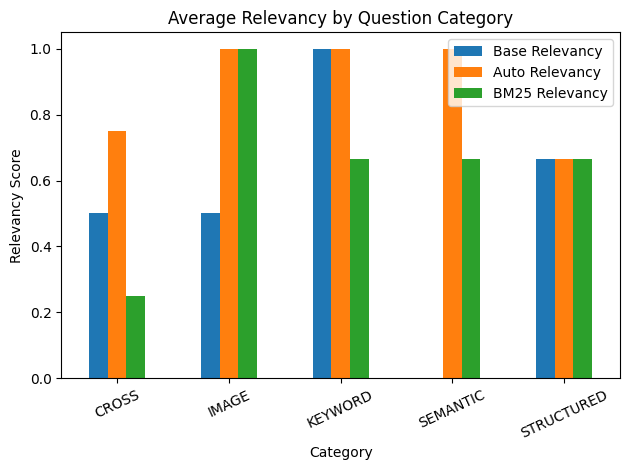

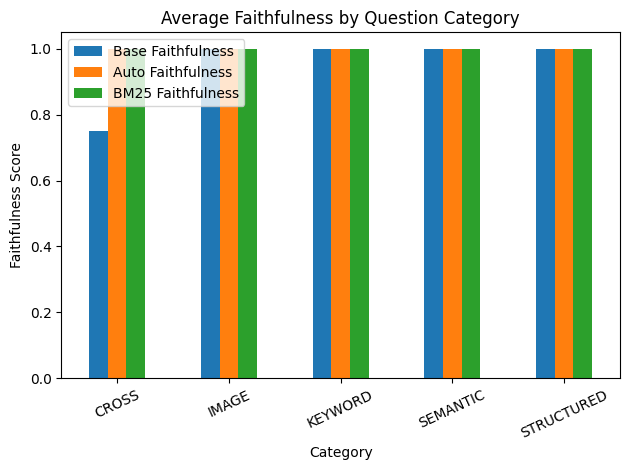

In [11]:
import matplotlib.pyplot as plt

# Average relevancy by category
cat_rel = df.groupby("Category")[["Base Relevancy","Auto Relevancy","BM25 Relevancy"]].mean()
ax = cat_rel.plot(kind="bar", rot=25)
ax.set_title("Average Relevancy by Question Category")
ax.set_ylabel("Relevancy Score")
plt.tight_layout()
plt.show()

# Average faithfulness by category
cat_faith = df.groupby("Category")[["Base Faithfulness","Auto Faithfulness","BM25 Faithfulness"]].mean()
ax = cat_faith.plot(kind="bar", rot=25)
ax.set_title("Average Faithfulness by Question Category")
ax.set_ylabel("Faithfulness Score")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

results = pd.DataFrame([
    # ---------- Baseline: 256 / 0 ----------
    {"setting":"Baseline (256/0)", "retriever":"Base",        "mrr":0.016393, "hit_rate":0.016393, "precision":0.016393, "recall":0.016393, "faithfulness":0.6667, "relevancy":0.3333},
    {"setting":"Baseline (256/0)", "retriever":"Auto-Merging","mrr":0.021858, "hit_rate":0.032787, "precision":0.010929, "recall":0.032787, "faithfulness":0.6667, "relevancy":0.6667},
    {"setting":"Baseline (256/0)", "retriever":"BM25",        "mrr":0.024590, "hit_rate":0.032787, "precision":0.016393, "recall":0.032787, "faithfulness":1.0000, "relevancy":0.3333},

    # ---------- Optimized: 512 / 100 ----------
    {"setting":"Optimized (512/100)", "retriever":"Base",        "mrr":0.031250, "hit_rate":0.031250, "precision":0.031250, "recall":0.031250, "faithfulness":1.0000, "relevancy":0.3333},
    {"setting":"Optimized (512/100)", "retriever":"Auto-Merging","mrr":0.057292, "hit_rate":0.093750, "precision":0.031250, "recall":0.093750, "faithfulness":1.0000, "relevancy":0.6667},
    {"setting":"Optimized (512/100)", "retriever":"BM25",        "mrr":0.046875, "hit_rate":0.062500, "precision":0.031250, "recall":0.062500, "faithfulness":1.0000, "relevancy":1.0000},
])

results

,setting,retriever,mrr,hit_rate,precision,recall,faithfulness,relevancy
0,Baseline (256/0),Base,0.016393,0.016393,0.016393,0.016393,0.6667,0.3333
1,Baseline (256/0),Auto-Merging,0.021858,0.032787,0.010929,0.032787,0.6667,0.6667
2,Baseline (256/0),BM25,0.024590,0.032787,0.016393,0.032787,1.0000,0.3333
3,Optimized (512/100),Base,0.031250,0.031250,0.031250,0.031250,1.0000,0.3333
4,Optimized (512/100),Auto-Merging,0.057292,0.093750,0.031250,0.093750,1.0000,0.6667
5,Optimized (512/100),BM25,0.046875,0.062500,0.031250,0.062500,1.0000,1.0000


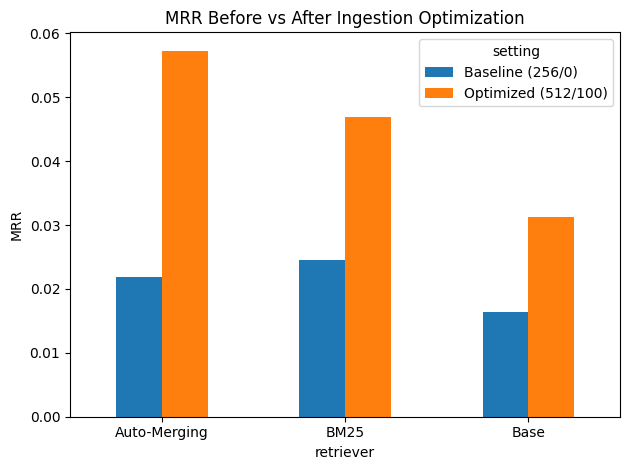

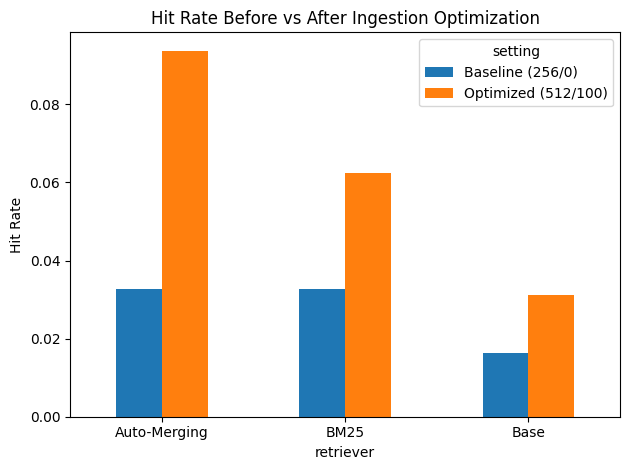

In [ ]:
import matplotlib.pyplot as plt

pivot_mrr = results.pivot(index="retriever", columns="setting", values="mrr")

ax = pivot_mrr.plot(kind="bar", rot=0)
ax.set_title("MRR Before vs After Ingestion Optimization")
ax.set_ylabel("MRR")
plt.tight_layout()
plt.show()

pivot_hit = results.pivot(index="retriever", columns="setting", values="hit_rate")

ax = pivot_hit.plot(kind="bar", rot=0)
ax.set_title("Hit Rate Before vs After Ingestion Optimization")
ax.set_ylabel("Hit Rate")
plt.tight_layout()
plt.show()